# Lecture 21 - LINEAR DATA FITTING WITH UNCERTANTIES - HW 10

As scientists one of our many checks is to fit data to models.  Here, we will begin first by learning how to fit data with uncertanties to a linear fit (slope and intercept, and uncertanties) by using the python `scipy` module. 

In [ ]:
#standard importing
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

In [4]:
#Read in the data to a numpy array
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)

# print out all columns we just got for free
data.dtype


dtype([('X', '<f8'), ('Y', '<f8'), ('Y_ERR', '<f8'), ('Z', '<f8'), ('Z_ERR', '<f8')])

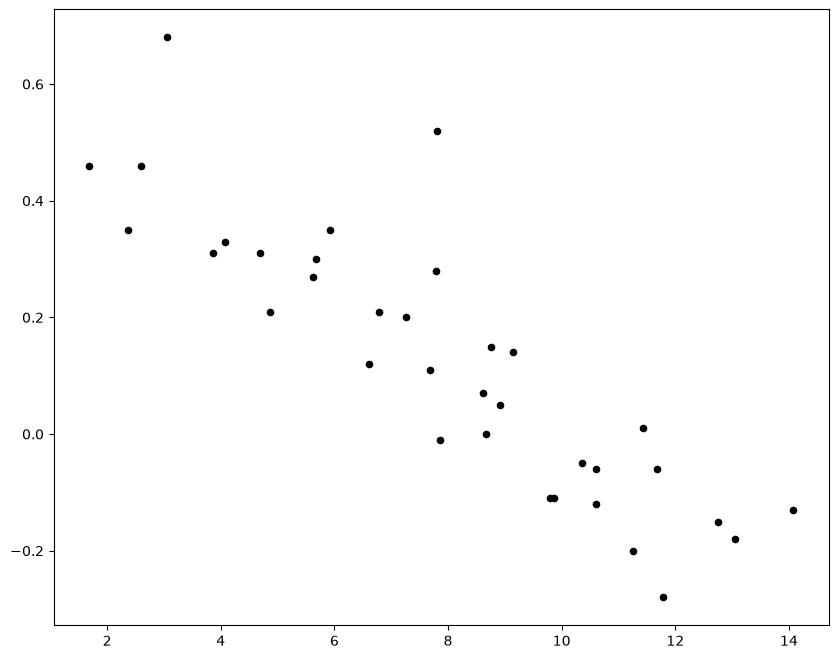

In [5]:
#First let's see what this data looks like
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black')

# Cool! The data actually looks pretty linear so we can assume the function we are fitting *is* linear

In [ ]:
# let's make a linear function the normal way
def linear(x, m, b):
    return m * x + b

raw:  -0.061902193408195354 0.6174204496164702
raw:  [ 3.63943117e-05 -2.88586095e-04] [-0.00028859  0.0026655 ]


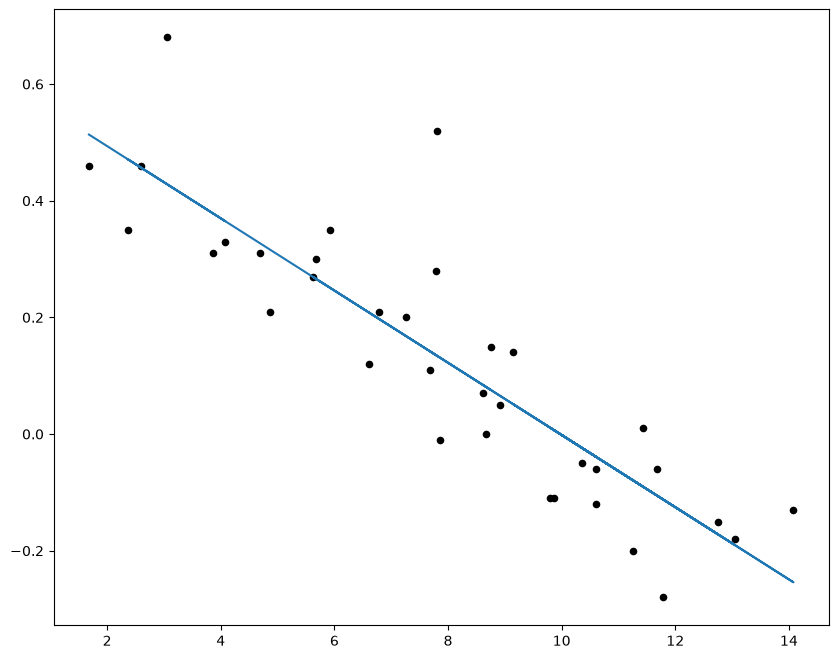

In [7]:

def linear(x, m, b):
    return m * x + b
# let's do a linear fit to the data

popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)
print("raw: ", *pcov)


fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black')
ax.plot(data['X'],linear(data['X'], *popt))


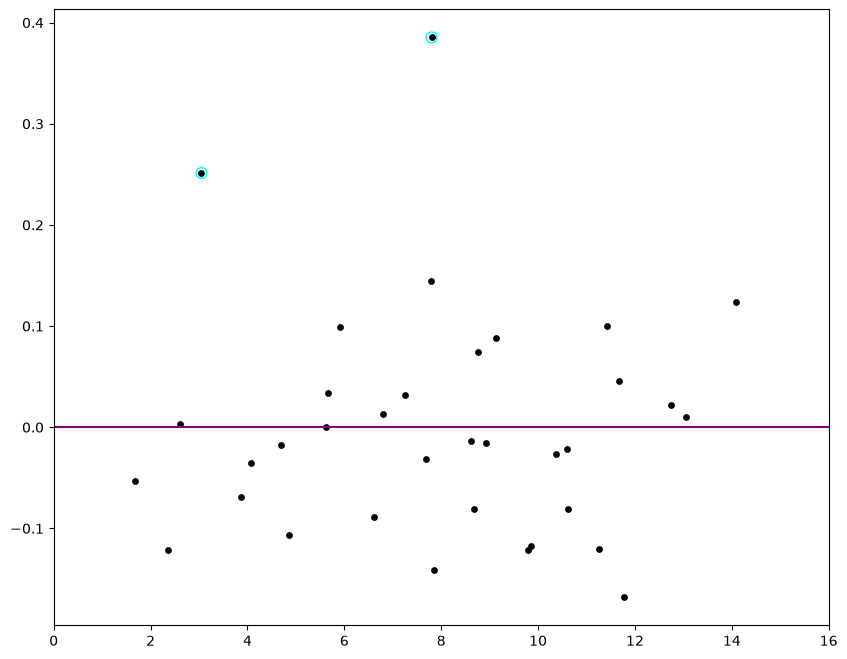

In [8]:
#Let's look into wich data are way off the fit.

residual = data['Y']-linear(data['X'],*popt)
x = np.linspace(0,20,1000)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],residual,s=15,c='black')
ax.plot(x,x*0.0,color='purple')
ax.set_xlim(0,16)

outlier = np.absolute(residual)>0.20
ax.scatter(data['X'][outlier],residual[outlier],s=60,edgecolor='cyan',facecolor='none')


raw:  -0.061902193408195354 0.6174204496164702
outliers accounted for:  -0.05813182372326915 0.570322076001352


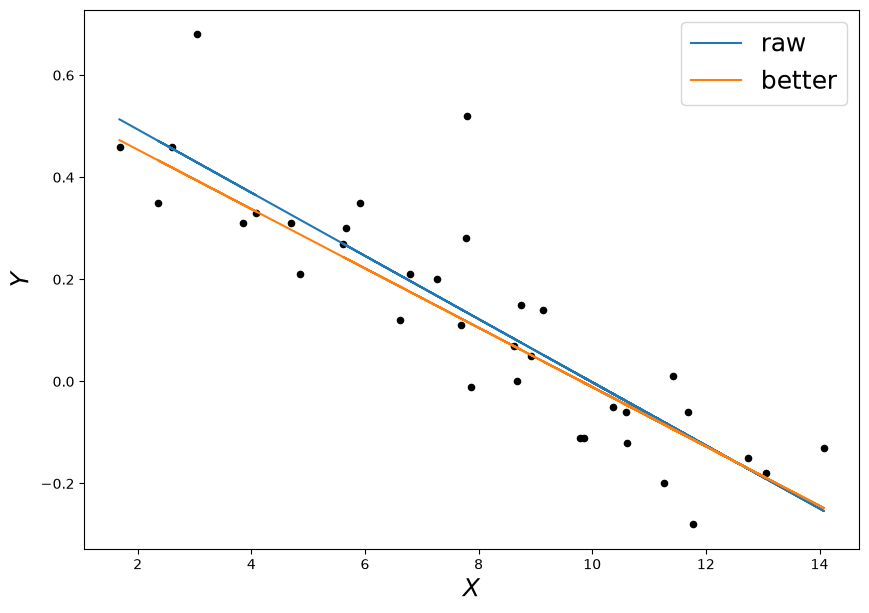

In [9]:
# our values for the raw data above:
# slope:    -0.058187
# intercept: 0.565351
popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)

# we can use curve_fit to de-weight outliers automatically

# note, result is dependent on choice of loss function
# need to see method to trf in order to use least_squares instead of leastsq
popt_clean, pcov = opt.curve_fit(linear, data['X'], data['Y'], method='trf', 
                                 loss='arctan', f_scale=0.20)
print("outliers accounted for: ", *popt_clean)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black',zorder=2)
# cleaner error bars than last time, play around with the parameters
#ax.errorbar(data['X'],data['Y'],yerr=data['Y_ERR'], c='tab:gray', 
#            fmt='.', markersize=1, capsize=3 ,zorder=0)

# along with our fits
ax.plot(data['X'],linear(data['X'], *popt), label='raw')
ax.plot(data['X'],linear(data['X'], *popt_clean), label='better')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

-0.05606558290562281 0.5500877315242667


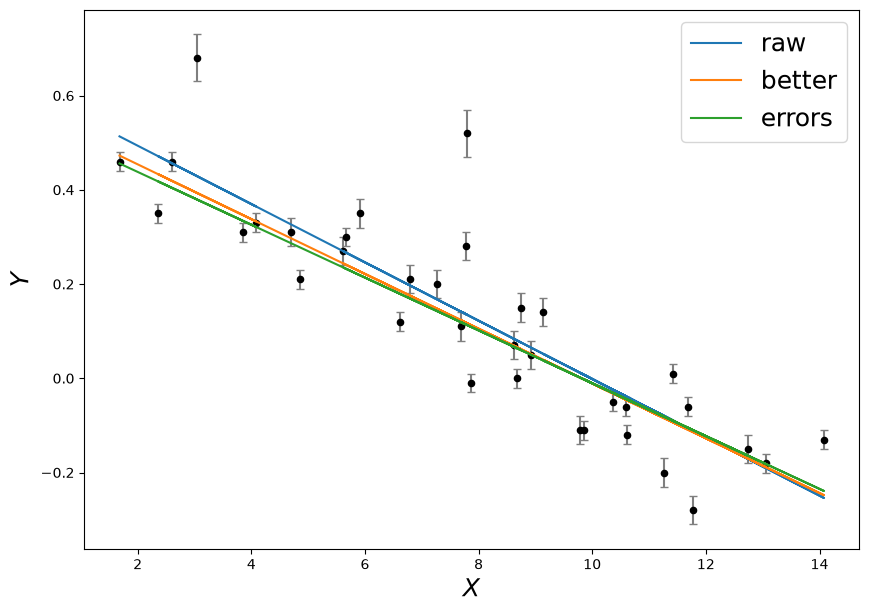

In [10]:
# lets account for the errors
# by pasing sigma, scipy knows to weight data according to their errors 
# naturally, sigma is expected to be the same size and correspond to y
# notice: this only accounts for y error
popt_err, pcov = opt.curve_fit(linear, data['X'], data['Y'], sigma=data['Y_ERR'])
print(*popt_err)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'],data['Y'],yerr=data['Y_ERR'], c='tab:gray', 
            fmt='.', markersize=1, capsize=3 ,zorder=0)

# along with out fits
ax.plot(data['X'],linear(data['X'], *popt), label='raw')
ax.plot(data['X'],linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'],linear(data['X'], *popt_err), label='errors')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

mean slope: -0.0619, mean intercept: 0.6171


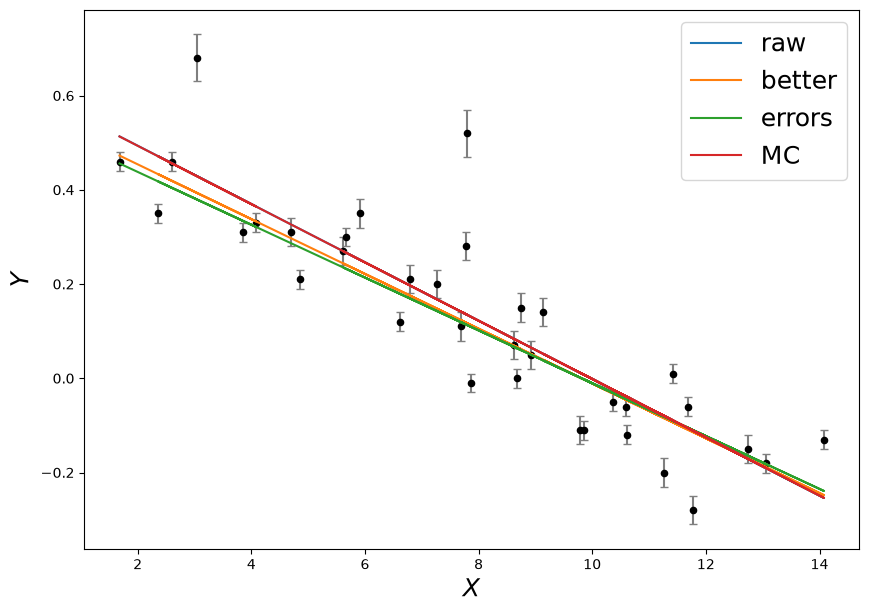

In [11]:
# Does this accurately explore the parameter space though?
# And what is the uncertainty on our data?
# What if we had x error bars?

# we'll explore a method utilizing the common "monte carlo" approach
def mcFit(x, y, y_err):
    slopes = list()
    y_ints = list()
    iters = 500 
    for i in range(iters):
        # remember random normal distribution (Gaussian)
        weights = np.random.randn(len(y))

        y_adj = y + y_err*weights
        x_adj = x  

        params, other = opt.curve_fit(linear, x_adj, y_adj)
        slopes.append(params[0])
        y_ints.append(params[1])
    
    return slopes, y_ints

slope, intercept = mcFit(data['X'], data['Y'], data['Y_ERR'])

print('mean slope: {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.mean(intercept)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'], c='tab:gray', 
            fmt='.', markersize=1, capsize=3 ,zorder=0)

# along with our fits
ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

In [12]:
# oh right, those outliers.

mask = data['Y'] < 0.5 

xdat = data['X'][mask]
ydat = data['Y'][mask]
ydat_err = data['Y_ERR'][mask]

print("data size: ", len(xdat))

slope, intercept = mcFit(xdat, ydat, ydat_err)

print('slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.std(slope),
                                                                          np.mean(intercept)))
print("\n")
# lets discuss monte carlo methods a little
for i in range(20):
    slope, intercept = mcFit(xdat, ydat, ydat_err)
    print("slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}".format(np.mean(slope), np.std(slope), 
                                                                          np.mean(intercept)))

# so what we see that our answer changes slightly, but its within the standard deviation
# of each set of measurements. So we can quote a reliable answer, with a reliable uncertainty

<>:13: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:19: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:13: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:19: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Amy\AppData\Local\Temp\ipykernel_30156\2451819757.py:13: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  print('slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.std(slope),
C:\Users\Amy\AppData\Local\Temp\ipykernel_30156\2451819757.py:19: Sy

data size:  33
slope: -0.0579 $\pm$ 0.0013, mean intercept: 0.5659


slope: -0.0578 $\pm$ 0.0013, mean intercept: 0.5650
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5653
slope: -0.0579 $\pm$ 0.0012, mean intercept: 0.5657
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5650
slope: -0.0578 $\pm$ 0.0013, mean intercept: 0.5654
slope: -0.0578 $\pm$ 0.0013, mean intercept: 0.5653
slope: -0.0579 $\pm$ 0.0013, mean intercept: 0.5659
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5650
slope: -0.0579 $\pm$ 0.0012, mean intercept: 0.5653
slope: -0.0577 $\pm$ 0.0012, mean intercept: 0.5639
slope: -0.0578 $\pm$ 0.0013, mean intercept: 0.5653
slope: -0.0579 $\pm$ 0.0012, mean intercept: 0.5656
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5655
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5650
slope: -0.0578 $\pm$ 0.0013, mean intercept: 0.5649
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5649
slope: -0.0578 $\pm$ 0.0012, mean intercept: 0.5653
slope: -0.0578 $\pm$ 0.0011, mean intercept: 0.

<>:18: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:19: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:18: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:19: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Amy\AppData\Local\Temp\ipykernel_30156\225136314.py:18: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax.text(2, -0.2, "Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope), np.std(slope)), fontsize=18)
C:\Users\Amy\AppData\Local\Temp\ipykernel_30156\225136314.py:19: Synt

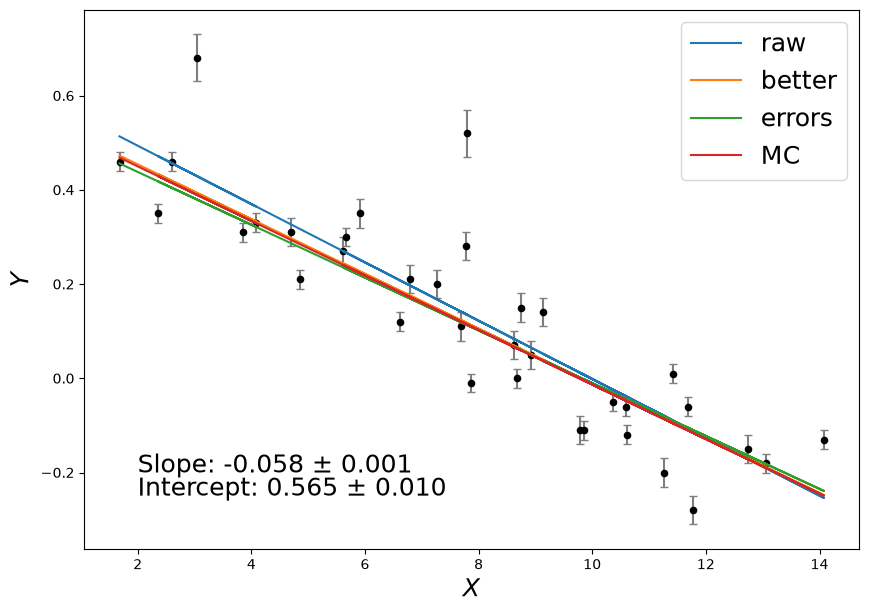

In [19]:
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'], c='tab:gray', 
            fmt='.', markersize=1, capsize=3 ,zorder=0)

slope, intercept = mcFit(xdat, ydat, ydat_err)

# along with out fits
ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

ax.text(2, -0.2, "Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope), np.std(slope)), fontsize=18)
ax.text(2, -0.25, "Intercept: {:5.3f} $\pm$ {:5.3f}".format(np.mean(intercept), np.std(intercept)), fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

## Homework #10

**REMINDER:** *All coding assignment will be turned in as .ipynb files, to the same PHYS_X0223 repository on GitHub.*   
*They should be turned in with the following naming:*
    
    Lastname_Firstinitial_25_HW10.ipynb

Problem 1:

We can't know the x data perfectly suppose the data have uniform x errors of 0.5 use the MC technique to estimate the slope AND the uncertainty taking into account these errors


In [2]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)
data.dtype

fig =plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'], s=20, c='black')

def linear(x,m,b):
    return m*x+b

popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)
print("raw: ", *pcov)

fig = plt.figure(figsize(10,8))
ax = fig.add_subplot(111)
ax.scatter(datadata['X'], data['Y'], s=20, c='black')
ax.plot(data['X'], linear(data['X'], *popt)

residual = data['Y'] -linear(data['X'], *popt)
x = np.linspace(0,20,1000)

fig =plt.figure(figsize=(10,8))
ax =fig.add_subplot(111)
ax.scatter(data['X'], residual, s=15, c='black')
ax.plot(x,x*0, color="purple")
ax.set_xlim(0,16)

outlier =np.absolute(residual) > 0.2
ax.scatter(data['X'][outlier], residual[outlier], s=60, c='pink')

popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)

popt_clean, pcov = opt.curve_fit(linear, data['X'], data['Y'], method ='trf', loss='arctan', f_scale=0.2)
print("outliers accounter for are : ", *popt_clean)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'], s=20, c='black', zorder=2)

ax.set_xlabel(('$X$', fontsize=18)
ax.set_ylabel(('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()


popt_err, pcov = opt.curve_fit(linear, data['X'], data['Y'], sigma=data['Y_ERR'])
print(*popt_err)

fig = plt.figure(figsize=(10,7))
ax =fig.add_subplot(111)
ax.scatter(data['X'], data['Y'], s=20, c="black", zorder =2)
ax.errorbar(data['X'], data['Y'], yerr=data['Y_ERR'], c="tab:gray", fmt= " ", markersize =1, capsize = 3, zorder =0)

ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)
              
plt.legend(loc='best', fontsize=18)
plt.show()              
                 
def mcFit(x, y, x_err, y_err):
    slopes = list()
    y_ints = list()
    iters = 500 
    for i in range(iters):
        # remember random normal distribution (Gaussian)
        weights = np.random.randn(len(y))
        weights_x = np.random.randn(len(x))

        y_adj = y + y_err*weights
        x_adj = x + x_err *weights_x

        params, other = opt.curve_fit(linear, x_adj, y_adj)
        slopes.append(params[0])
        y_ints.append(params[1])
        return slopes, y_ints

slope, intercept = mcFit(data['X'], data['Y'], 0.5, data['Y_ERR'])

print('mean slope: {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.mean(intercept)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'], xerr=0.5, c='tab:gray', fmt='.', markersize=1, capsize=3 ,zorder=0)

# along with our fits
ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

mask = data['Y'] < 0.5 

xdat = data['X'][mask]
ydat = data['Y'][mask]
ydat_err = data['Y_ERR'][mask]

print("data size: ", len(xdat))

slope, intercept = mcFit(xdat, ydat,0.5, ydat_err)

print('slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.std(slope), np.mean(intercept)))
print("\n")
# lets discuss monte carlo methods a little
for i in range(20):
    slope, intercept = mcFit(xdat, ydat,0.5, ydat_err)
    print("slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}".format(np.mean(slope), np.std(slope), np.mean(intercept)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'],xerr =0.5, c='tab:gray', fmt='.', markersize=1, capsize=3 ,zorder=0)

slope, intercept = mcFit(xdat, ydat, 0.5, ydat_err)

# along with out fits
ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

ax.text(2, -0.2, "Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope), np.std(slope)), fontsize=18)
ax.text(2, -0.25, "Intercept: {:5.3f} $\pm$ {:5.3f}".format(np.mean(intercept), np.std(intercept)), fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()


SyntaxError: invalid syntax. Perhaps you forgot a comma? (1654117052.py, line 23)

raw:  -0.061902193408195354 0.6174204496164702
raw:  [ 3.63943117e-05 -2.88586095e-04] [-0.00028859  0.0026655 ]
raw:  -0.061902193408195354 0.6174204496164702
outliers accounted for:  -0.05813182372326915 0.570322076001352


<>:116: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:120: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:138: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:139: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:116: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:120: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:138: SyntaxWarning: "\p" is an invalid escape sequence. Such sequen

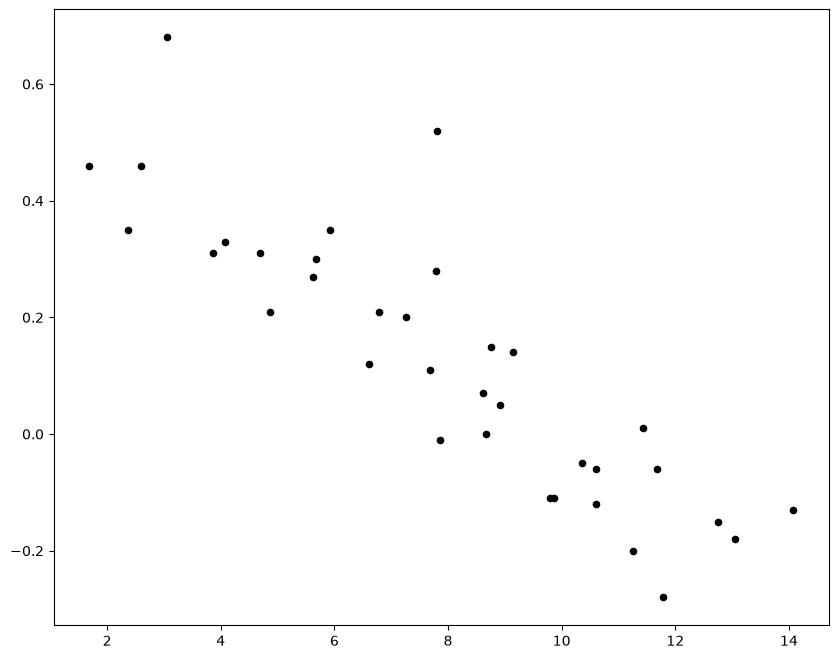

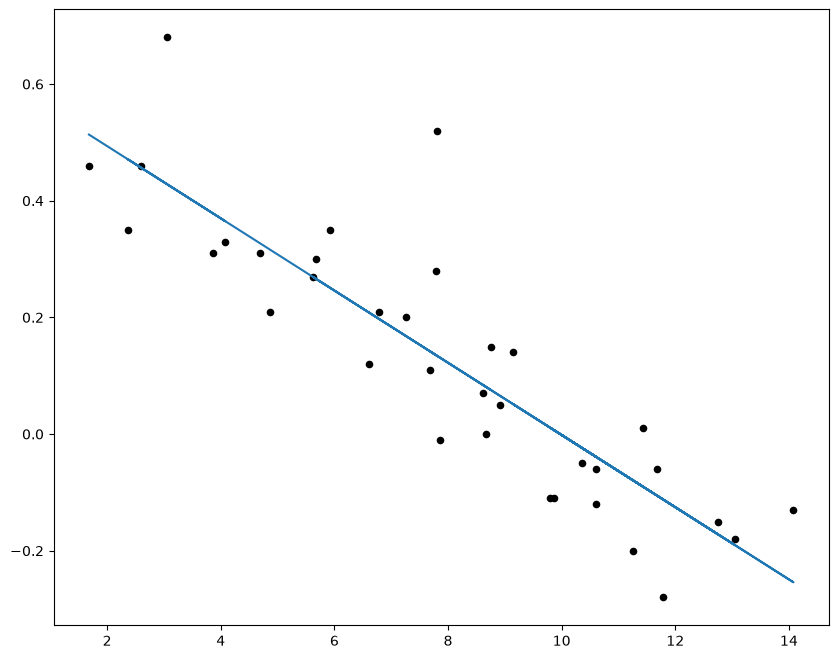

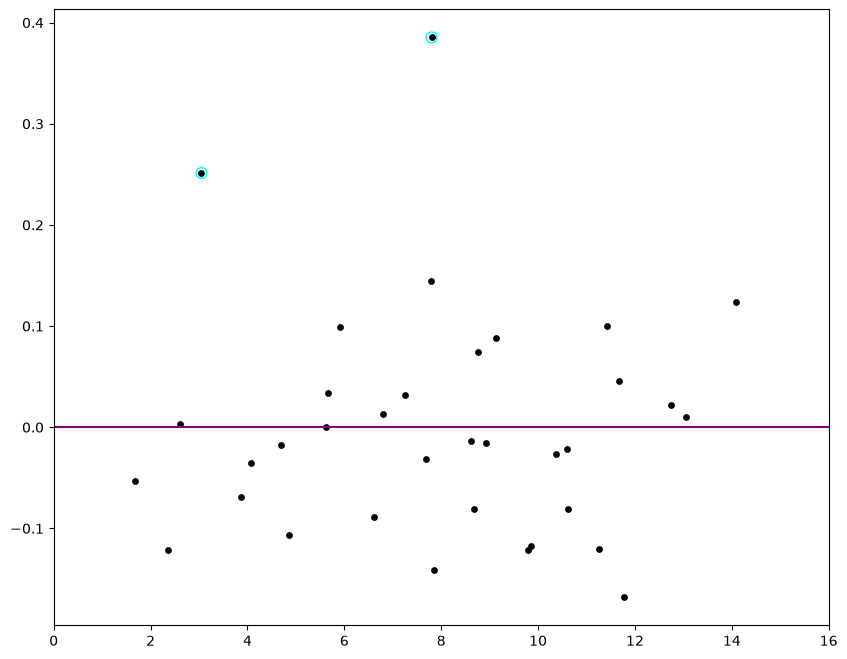

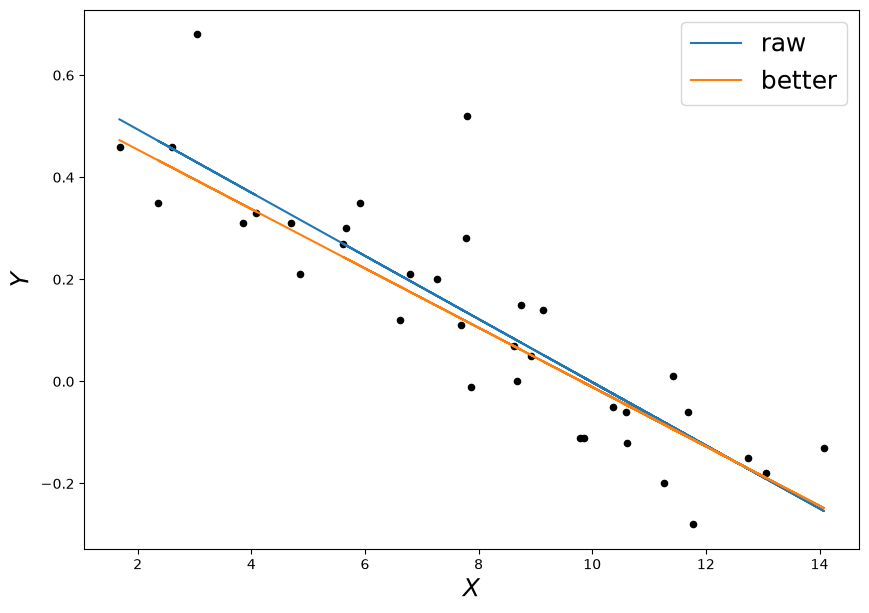

-0.05606558290562281 0.5500877315242667


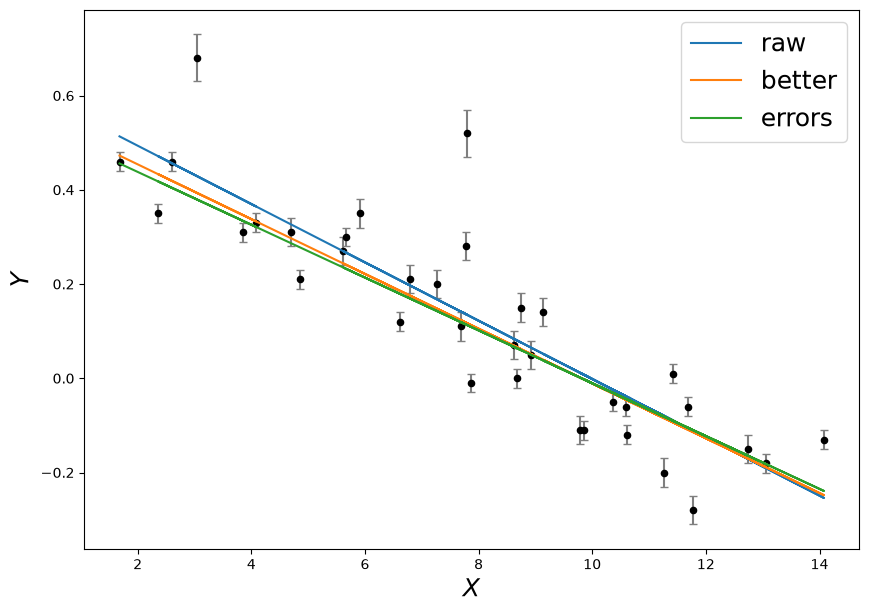

mean slope: -0.0605, mean intercept: 0.6063


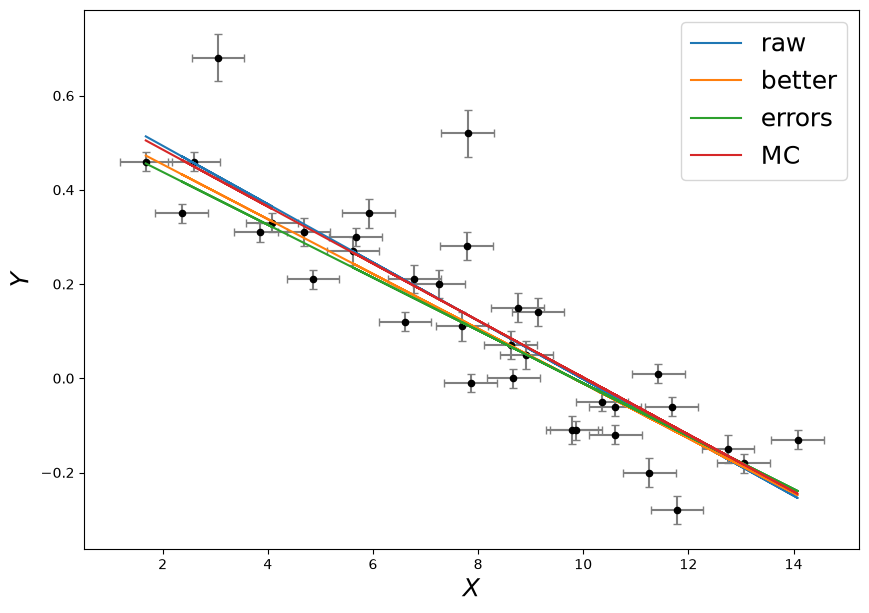

data size:  33
slope: -0.0566 $\pm$ 0.0021, mean intercept: 0.5549


slope: -0.0565 $\pm$ 0.0021, mean intercept: 0.5543
slope: -0.0567 $\pm$ 0.0021, mean intercept: 0.5558
slope: -0.0564 $\pm$ 0.0019, mean intercept: 0.5536
slope: -0.0566 $\pm$ 0.0021, mean intercept: 0.5555
slope: -0.0565 $\pm$ 0.0022, mean intercept: 0.5547
slope: -0.0566 $\pm$ 0.0020, mean intercept: 0.5551
slope: -0.0565 $\pm$ 0.0021, mean intercept: 0.5540
slope: -0.0564 $\pm$ 0.0021, mean intercept: 0.5543
slope: -0.0565 $\pm$ 0.0021, mean intercept: 0.5546
slope: -0.0564 $\pm$ 0.0020, mean intercept: 0.5539
slope: -0.0564 $\pm$ 0.0020, mean intercept: 0.5533
slope: -0.0566 $\pm$ 0.0022, mean intercept: 0.5551
slope: -0.0566 $\pm$ 0.0021, mean intercept: 0.5555
slope: -0.0565 $\pm$ 0.0021, mean intercept: 0.5549
slope: -0.0566 $\pm$ 0.0021, mean intercept: 0.5550
slope: -0.0566 $\pm$ 0.0020, mean intercept: 0.5553
slope: -0.0566 $\pm$ 0.0021, mean intercept: 0.5560
slope: -0.0567 $\pm$ 0.0021, mean intercept: 0.

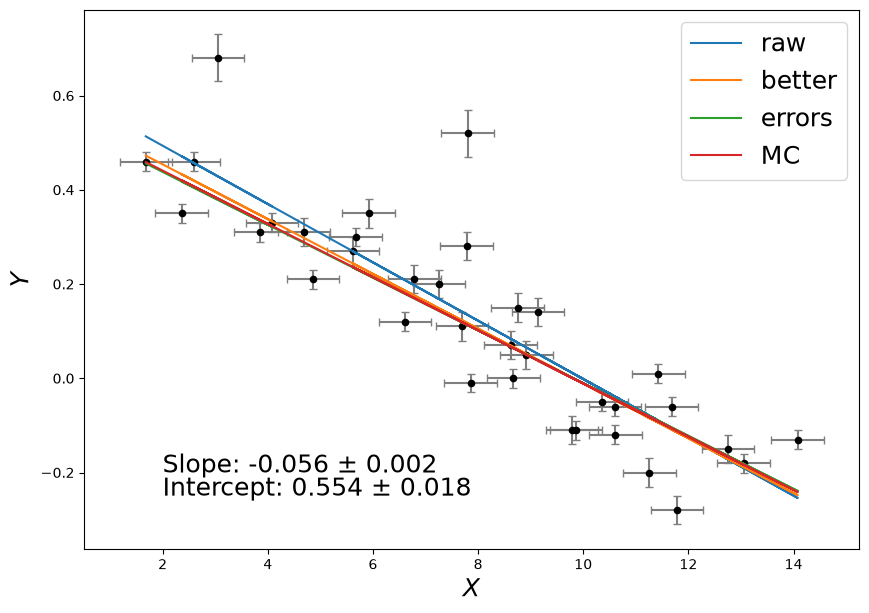

In [4]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)
data.dtype
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black')

def linear(x, m, b):
    return m * x + b
popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)
print("raw: ", *pcov)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black')
ax.plot(data['X'],linear(data['X'], *popt))

residual = data['Y']-linear(data['X'],*popt)
x = np.linspace(0,20,1000)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111)
ax.scatter(data['X'],residual,s=15,c='black')
ax.plot(x,x*0.0,color='purple')
ax.set_xlim(0,16)

outlier = np.absolute(residual)>0.20
ax.scatter(data['X'][outlier],residual[outlier],s=60,edgecolor='cyan',facecolor='none')

popt, pcov = opt.curve_fit(linear, data['X'], data['Y'])
print("raw: ", *popt)
popt_clean, pcov = opt.curve_fit(linear, data['X'], data['Y'], method='trf',loss='arctan', f_scale=0.20)
print("outliers accounted for: ", *popt_clean)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black',zorder=2)

ax.plot(data['X'],linear(data['X'], *popt), label='raw')
ax.plot(data['X'],linear(data['X'], *popt_clean), label='better')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

popt_err, pcov = opt.curve_fit(linear, data['X'], data['Y'], sigma=data['Y_ERR'])
print(*popt_err)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'],data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'],data['Y'],yerr=data['Y_ERR'], c='tab:gray', fmt='.', markersize=1, capsize=3 ,zorder=0)

ax.plot(data['X'],linear(data['X'], *popt), label='raw')
ax.plot(data['X'],linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'],linear(data['X'], *popt_err), label='errors')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()
def mcFit(x, y, x_err, y_err):
    slopes = list()
    y_ints = list()
    iters = 500

    for i in range(iters):
        weights = np.random.randn(len(y))
        weights_x = np.random.randn(len(x))

        y_adj = y + y_err*weights
        x_adj = x + x_err*weights_x

        params, other = opt.curve_fit(linear, x_adj, y_adj)
        slopes.append(params[0])
        y_ints.append(params[1])

    return slopes, y_ints

slope, intercept = mcFit(data['X'], data['Y'], 0.5, data['Y_ERR'])

print('mean slope: {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.mean(intercept)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'], xerr=0.5, c='tab:gray',fmt='.', markersize=1, capsize=3 ,zorder=0)
ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()

mask = data['Y'] < 0.5

xdat = data['X'][mask]
ydat = data['Y'][mask]
ydat_err = data['Y_ERR'][mask]

print("data size: ", len(xdat))

slope, intercept = mcFit(xdat, ydat, 0.5, ydat_err)

print('slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}'.format(np.mean(slope), np.std(slope), np.mean(intercept)))
print("\n")
for i in range(20):
    slope, intercept = mcFit(xdat, ydat, 0.5, ydat_err)
    print("slope: {:+7.4f} $\pm$ {:6.4f}, mean intercept: {:6.4f}".format(np.mean(slope), np.std(slope), np.mean(intercept)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'],s=20,c='black',zorder=2)
ax.errorbar(data['X'], data['Y'],yerr=data['Y_ERR'], xerr=0.5, c='tab:gray',
             fmt='.', markersize=1, capsize=3 ,zorder=0)

slope, intercept = mcFit(xdat, ydat, 0.5, ydat_err)

ax.plot(data['X'], linear(data['X'], *popt), label='raw')
ax.plot(data['X'], linear(data['X'], *popt_clean), label='better')
ax.plot(data['X'], linear(data['X'], *popt_err), label='errors')
ax.plot(data['X'], linear(data['X'], np.mean(slope), np.mean(intercept)), label='MC')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

ax.text(2, -0.2, "Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope), np.std(slope)), fontsize=18)
ax.text(2, -0.25, "Intercept: {:5.3f} $\pm$ {:5.3f}".format(np.mean(intercept), np.std(intercept)), fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()


### Problem 2:
Repeat problem #1 , but change the errors INCREASE as we move away from X = 8 (as they do) to be precise: suppose X_ERR = |x - 8| /10, e.g. it increases by .1 per unit.

Plot both slopes (Problem 1 & 2). How does the fit change? 

<>:32: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:47: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:48: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:32: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:38: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:47: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences wil

Problem 1 slope: -0.0537 $\pm$ 0.0000, intercept: 0.5306 $\pm$ 0.0000
Problem 2 slope: -0.0570 $\pm$ 0.0000, intercept: 0.5578 $\pm$ 0.0000


AttributeError: PathCollection.set() got an unexpected keyword argument 'xerr'

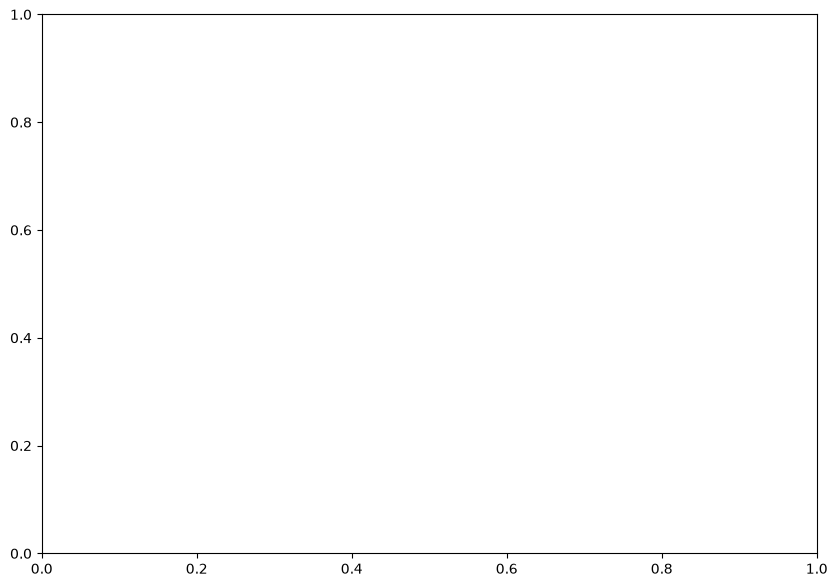

In [9]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt",names= True, dtype=None)
def linear(x, m,b):
    return m*x +b

def mcFit(x, y, x_err, y_err):
    slopes = list()
    y_ints = list()
    iters =500

    for i in range(iters):
        weights =np.random.randn(len(y))
        weights_x = np.random.randn(len(x))
        y_adj = y +y_err*weights
        x_adj =x + x_err*weights_x

        params, other =opt.curve_fit(linear, x_adj, y_adj)
        slopes.append(params[0])
        y_ints.append(params[1])
        return slopes,y_ints

mask =data['Y'] <0.5
xdat = data['X'][mask]
ydat = data['Y'][mask]
ydat_err = data['Y_ERR'][mask]

xdat_err1 =0.5
slope1, intercept1 =mcFit(xdat, ydat, xdat_err1, ydat_err)
print("Problem 1 slope: {:+7.4f} $\pm$ {:6.4f}, intercept: {:6.4f} $\pm$ {:6.4f}".format(np.mean(slope1), np.std(slope1), np.mean(intercept1), np.std(intercept1)))

x_err_all = np.absolute(data['X'] -8) /10
xdat_err2= np.absolute(xdat -8) /10

slope2, intercept2 = mcFit(xdat, ydat, xdat_err2, ydat_err)
print("Problem 2 slope: {:+7.4f} $\pm$ {:6.4f}, intercept: {:6.4f} $\pm$ {:6.4f}".format(np.mean(slope2), np.std(slope2), np.mean(intercept2), np.std(intercept2)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'], data['Y_ERR'], xerr=x_err_all, c='tab:gray', fmt='.', markersize =1, capsize=3, zorder= 0)

ax.plot(data['X'], linear(data['X'], np.mean(slope1), np.mean(intercept1)), label='Problem 1 (X_ERR = 0.5)')
ax.plot(data['X'], linear(data['X'], np.mean(slope2), np.mean(intercept2)), label='Problem 2 (X_ERR = |X - 8|/10)')

ax.text(2, -0.15, "Problem 1 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope1), np.std(slope1)), fontsize=18)
ax.text(2, -0.22, "Problem 2 Slope: {:5.3f} $\pm$ {:5.3f}".format(np.mean(slope2), np.std(slope2)), fontsize=18)

plt.legend(loc='best', fontsize=18)
plt.show()


<>:35: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:41: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:55: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:56: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:35: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:41: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:55: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences wil

Problem 1 Slope: -0.0567 $\pm$ 0.0021, Intercept: 0.5560 $\pm$ 0.0179
Problem 2 Slope: -0.0573 $\pm$ 0.0020, Intercept: 0.5610 $\pm$ 0.0168


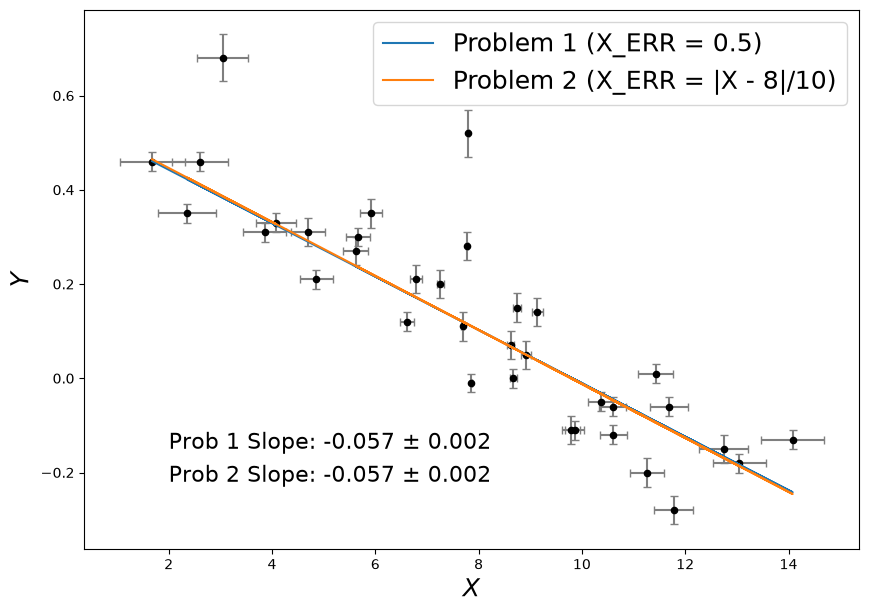

In [10]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)

def linear(x, m, b):
    return m * x + b

def mcFit(x, y, x_err, y_err):
    slopes = list()
    y_ints = list()
    iters = 500

    for i in range(iters):
        weights = np.random.randn(len(y))
        weights_x = np.random.randn(len(x))

        y_adj = y + y_err*weights
        x_adj = x + x_err*weights_x

        params, other = opt.curve_fit(linear, x_adj, y_adj)
        slopes.append(params[0])
        y_ints.append(params[1])
    return slopes, y_ints
mask = data['Y'] < 0.5

xdat = data['X'][mask]
ydat = data['Y'][mask]
ydat_err = data['Y_ERR'][mask]

xdat_err1 = 0.5
slope1, intercept1 = mcFit(xdat, ydat, xdat_err1, ydat_err)

print('Problem 1 Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope1), np.std(slope1), np.mean(intercept1), np.std(intercept1)))
x_err_all = np.absolute(data['X'] - 8) / 10
xdat_err2 = np.absolute(xdat - 8) / 10

slope2, intercept2 = mcFit(xdat, ydat, xdat_err2, ydat_err)

print('Problem 2 Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope2), np.std(slope2), np.mean(intercept2), np.std(intercept2)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Y'], s=20, c='black', zorder=2)
ax.errorbar(data['X'], data['Y'], yerr=data['Y_ERR'], xerr=x_err_all, c='tab:gray', fmt='.', markersize=1, capsize=3, zorder=0)

# Plot both MC lines
ax.plot(data['X'], linear(data['X'], np.mean(slope1), np.mean(intercept1)), label='Problem 1 (X_ERR = 0.5)')
ax.plot(data['X'], linear(data['X'], np.mean(slope2), np.mean(intercept2)), label='Problem 2 (X_ERR = |X - 8|/10)')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Y$', fontsize=18)

ax.text(2, -0.15, "Prob 1 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope1), np.std(slope1)), fontsize=16)
ax.text(2, -0.22, "Prob 2 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope2), np.std(slope2)), fontsize=16)

plt.legend(loc='best', fontsize=18)
plt.show()

The fit changes whenever the x errors grow larger and move farther away from X = 8, with the line getting more
flatter, the uncertainty growing larger.


### Problem 3: 
Repeat problem 1 & 2, but now anaylze for X vs. Z data, including both uniform 0.5 and X_ERR = |x - 8| /10 uncertainties.

In [17]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt

data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)

def linear(x, m, b):
    return m * x + b

def mcFit(x, z, x_err, z_err):
    slopes = list()
    z_ints = list()
    iters = 500

    for i in range(iters):
        weights = np.random.randn(len(z))
        weights_x = np.random.randn(len(x))
        z_adj = z + z_err*weights
        x_adj = x + x_err*weights_x
        params, other = opt.curve_fit(linear, x_adj, z_adj)
        slopes.append(params[0])
        z_ints.append(params[1])
        return slopes, z_ints
    
popt, pcov =opt.curve_fit(linear, data['X'], data['Z'])
residual = data['Z'] -linear(data['X'], *popt)

fig =plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], residual, s=15, c="black")
ax.plot(data['X'], data['X']*0, color="pink")
ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('Z Residual', fontsize=18)
plt.show()

mask = np.absolute(residual) <0.2
xdat= data['X'][mask]
zdat =data['Z'][mask]
zdat_err = data['Z_ERR'][mask]

print("data size: ", len(xdat))
xdat_err1 =0.5
slope1, intercept1 = mcFit(xdat, zdat, xdat_err1, zdat_err)
print('Problem 1(x vsZ) Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope1), np.std(slope1), np.mean(intercept1), np.std(intercept1)))
x_err_all = np.absolute(data['X'] - 8) / 10
xdat_err2 = np.absolute(xdat - 8) / 10

slope2, intercept2 = mcFit(xdat, zdat, xdat_err2, zdat_err)
print('Problem 2 (X vs Z)Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope2), np.std(slope2), np.mean(intercept2), np.std(intercept2)))

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Z'], s=20, c='black', zorder=2)
ax.errorbar(data['X'], data['Z'], yerr=data['Z_ERR'], xerr=x_err_all, c='tab:gray', fmt='.', markersize=1, capsize=3, zorder=0)

ax.plot(data['X'], linear(data['X'], np.mean(slope1), np.mean(intercept1)), label='Problem 1 (X_ERR = 0.5)')
ax.plot(data['X'], linear(data['X'], np.mean(slope2), np.mean(intercept2)), label='Problem 2 (X_ERR = |X - 8|/10)')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Z$', fontsize=18)

ax.text(2, np.min(data['Z'], "Problem 1 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope1), np.std(slope1)), fontsize=16))
ax.text(2, np.min(data['Z'] -0.5, "Problem 2 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope2), np.std(slope2), fontsize=16))

plt.legend(loc='best', fontsize=18)
plt.show()




<>:44: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:49: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:62: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:63: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:44: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:49: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:62: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences wil

SyntaxError: '(' was never closed (3905869357.py, line 63)

<>:42: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:48: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:58: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:59: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:42: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:48: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:58: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences wil

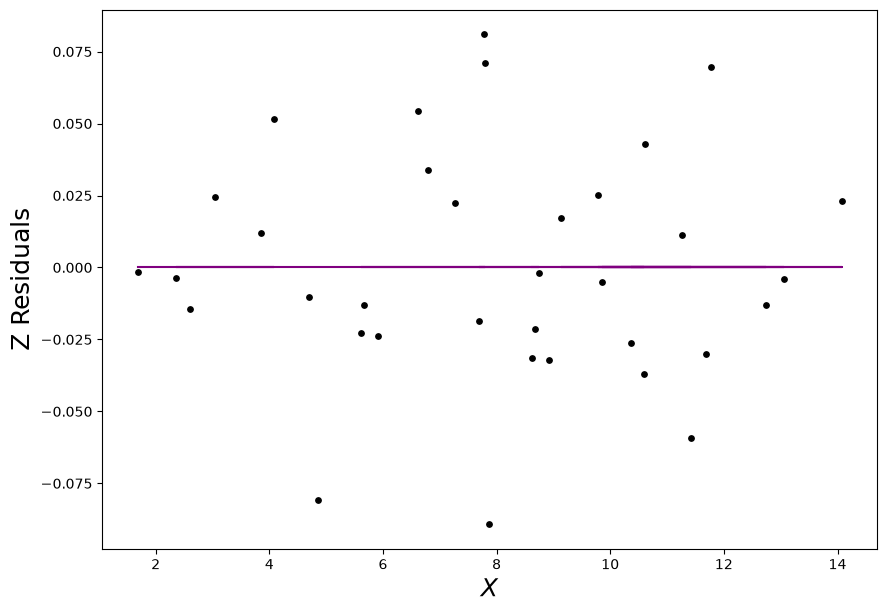

data size:  35
Problem 1 (X vs Z) Slope: +0.0027 $\pm$ 0.0035, Intercept: -0.0217 $\pm$ 0.0283
Problem 2 (X vs Z) Slope: +0.0027 $\pm$ 0.0036, Intercept: -0.0219 $\pm$ 0.0289


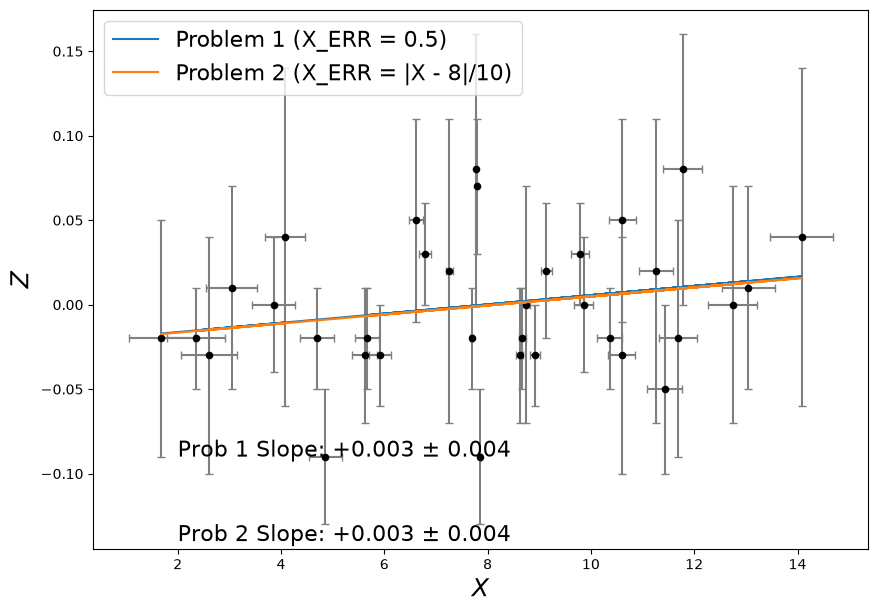

In [18]:
from matplotlib import pyplot as plt
import numpy as np
import scipy.optimize as opt
data = np.genfromtxt("LinearFit_data.txt", names=True, dtype=None)
def linear(x, m, b):
    return m * x +b

def mcFit(x, z, x_err, z_err):
    slopes = list()
    z_ints = list()
    iters = 500

    for i in range(iters):
        weights = np.random.randn(len(z))
        weights_x = np.random.randn(len(x))
        z_adj = z + z_err*weights
        x_adj = x + x_err*weights_x
        params, other = opt.curve_fit(linear, x_adj, z_adj)
        slopes.append(params[0])
        z_ints.append(params[1])
    return slopes, z_ints
popt, pcov = opt.curve_fit(linear, data['X'], data['Z'])
residual = data['Z'] - linear(data['X'], *popt)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], residual, s=15, c='black')
ax.plot(data['X'], data['X']*0, color='purple')
ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('Z Residuals', fontsize=18)
plt.show()
mask = np.absolute(residual) < 0.2

xdat = data['X'][mask]
zdat = data['Z'][mask]
zdat_err = data['Z_ERR'][mask]
print("data size: ", len(xdat))

xdat_err1 = 0.5
slope1, intercept1 = mcFit(xdat, zdat, xdat_err1, zdat_err)

print('Problem 1 (X vs Z) Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope1), np.std(slope1), np.mean(intercept1), np.std(intercept1)))
x_err_all = np.absolute(data['X'] - 8) / 10
xdat_err2 = np.absolute(xdat - 8) / 10

slope2, intercept2 = mcFit(xdat, zdat, xdat_err2, zdat_err)

print('Problem 2 (X vs Z) Slope: {:+7.4f} $\pm$ {:6.4f}, Intercept: {:6.4f} $\pm$ {:6.4f}'.format(np.mean(slope2), np.std(slope2), np.mean(intercept2), np.std(intercept2)))
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111)
ax.scatter(data['X'], data['Z'], s=20, c='black', zorder=2)
ax.errorbar(data['X'], data['Z'], yerr=data['Z_ERR'], xerr=x_err_all, c='tab:gray', fmt='.', markersize=1, capsize=3, zorder=0)
ax.plot(data['X'], linear(data['X'], np.mean(slope1), np.mean(intercept1)), label='Problem 1 (X_ERR = 0.5)')
ax.plot(data['X'], linear(data['X'], np.mean(slope2), np.mean(intercept2)), label='Problem 2 (X_ERR = |X - 8|/10)')

ax.set_xlabel('$X$', fontsize=18)
ax.set_ylabel('$Z$', fontsize=18)
ax.text(2, np.min(data['Z']), "Prob 1 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope1), np.std(slope1)), fontsize=16)
ax.text(2, np.min(data['Z']) - 0.05, "Prob 2 Slope: {:+5.3f} $\pm$ {:5.3f}".format(np.mean(slope2), np.std(slope2)), fontsize=16)

plt.legend(loc='best', fontsize=16)
plt.show()
